# One-page speaker attribution: OCR versus image only

Use the **AppliedTaskByte** kernel. This notebook loads local Qwen once and performs two inference runs on exactly the same annotated page:

1. Image + group IDs/boxes + our OCR text.
2. Image + the same group IDs/boxes, with **no transcript in the prompt**.

The second run can read the text printed in the image. Both runs return one speaker label per group. This tests one-page attribution; it does not train or evaluate cross-page character consistency. Close other GPU model kernels before loading Qwen here.


In [ ]:
from pathlib import Path
import hashlib
import importlib.util
import json
import random
import re
import time

# Find the project even when this notebook starts inside its own directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'TaskData').is_dir() or (p / 'manga_notebook_codebase/TaskData').is_dir())
if not (ROOT / 'TaskData').is_dir():
    ROOT = ROOT / 'manga_notebook_codebase'
ROOT = ROOT.resolve()

MODEL_PATH = Path(r'C:\MODELS\HF\Qwen2.5-VL-3B-Instruct')
PREP_DIR = ROOT / 'outputs/transcript_prep_vl/val'
SEQUENCE_ID = seq_0dc2e3d874c804fc  # None selects the first prepared validation sequence.
PAGE_INDEX = 0      # 0, 1, or 2. Only this one page is passed to the model.
MIN_PIXELS = 128 * 28 * 28
MAX_PIXELS = 384 * 28 * 28  # One image, with a smaller budget than the triplet run.
MAX_NEW_TOKENS = 512
SEED = 42
RESULT_PATH = ROOT / 'outputs/bubble_speaker_attribution/single_page_comparison.json'


## 1. Select and inspect one image

Use the existing annotations so both runs see the same red group boxes and IDs. OCR text comes from the prepared page, not from the reference transcript. Increase MAX_PIXELS if the resized IDs are too small to inspect.


seq_b8b5563330fdc89d page 0 groups 13
Original image size: (800, 1200)


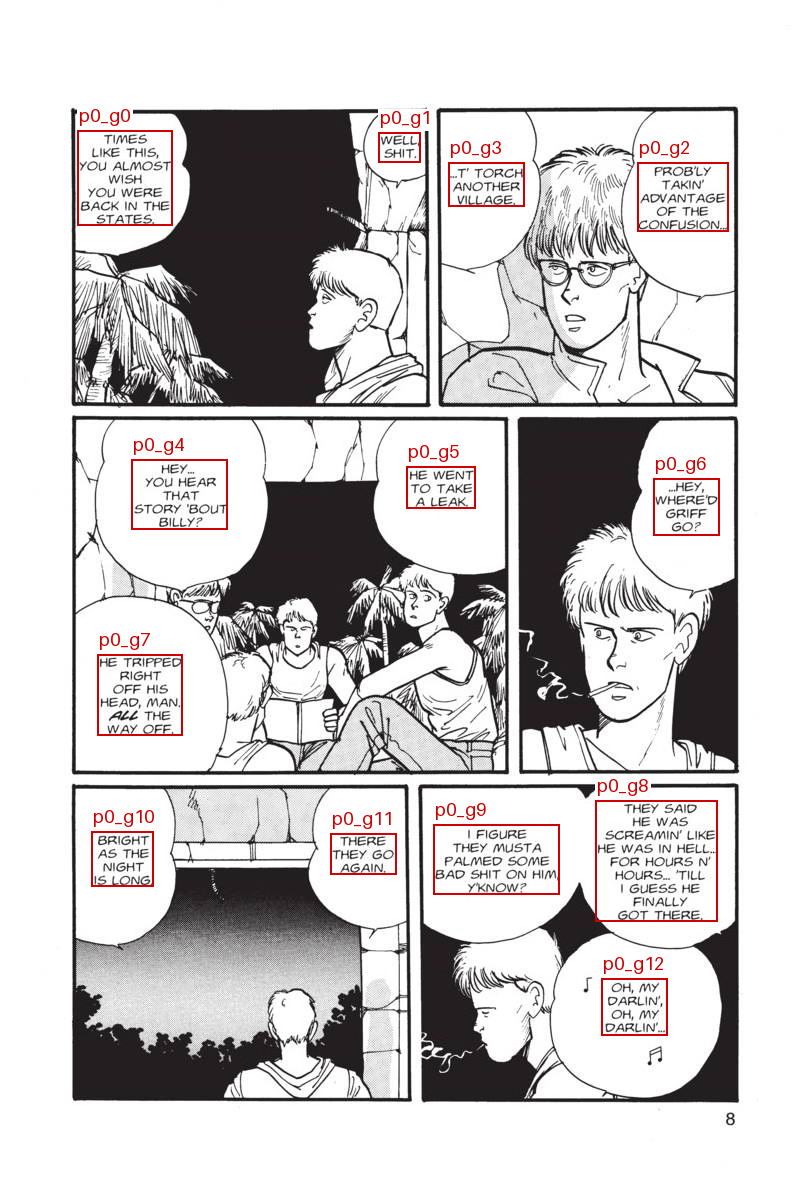

In [3]:
from PIL import Image
from IPython.display import display

records = [json.loads(line) for line in (PREP_DIR / 'inputs.jsonl').read_text(encoding='utf-8').splitlines()
           if line.strip()]
if not records:
    raise ValueError('Run validation transcript preparation first.')
if PAGE_INDEX not in (0, 1, 2):
    raise ValueError('PAGE_INDEX must be 0, 1, or 2')
sequence = records[0] if SEQUENCE_ID is None else next(
    record for record in records if record['sequence_id'] == SEQUENCE_ID)
page = sequence['pages'][PAGE_INDEX]
groups = page['groups']  # Keep saved order; do not alphabetically sort IDs.
if not groups:
    raise ValueError('Select a page containing OCR groups.')
image_path = (PREP_DIR / page['image']).resolve()
if not image_path.is_relative_to(PREP_DIR.resolve()) or not image_path.is_file():
    raise ValueError('Missing or unsafe annotated image path')
with Image.open(image_path) as source:
    page_image = source.convert('RGB')
print(sequence['sequence_id'], 'page', PAGE_INDEX, 'groups', len(groups))
print('Original image size:', page_image.size)
display(page_image)


## 2. Build the two prompts

Only the OCR-text lines differ. Instructions, group order, boxes, image, decoding settings, and output format are identical. Character numbers are arbitrary within each response.


In [5]:
def build_page_prompt(groups, include_ocr):
    lines = [
        'Identify the speaker of each marked text group on this single manga page.',
        'Red rectangles and labels identify the requested groups.',
        'Boxes use original-image pixels: [left, top, right, bottom].',
        'Use the image to connect each bubble or text region to its speaking character.',
        'Return exactly one speaker label per line, in the group order below.',
        'Use char1, char2, char3, ... for distinct characters.',
        'Use the same label whenever the same character speaks on this page.',
        'Different characters must have different labels. Character numbering is arbitrary.',
        'Use NARRATION for narrator text and UNKNOWN when the speaker cannot be determined.',
        'Do not output IDs, transcripts, JSON, explanations, or extra text.',
        '', 'Groups:',
    ]
    for group in groups:
        line = f"{group['id']}: box={json.dumps(group['box'])}"
        if include_ocr:
            # Quote OCR safely so embedded newlines do not change group order.
            line += ' text=' + json.dumps(group['text'], ensure_ascii=False)
        lines.append(line)
    return '\n'.join(lines)


prompts = {
    'with_ocr': build_page_prompt(groups, include_ocr=True),
    'without_transcript': build_page_prompt(groups, include_ocr=False),
}
for name, prompt in prompts.items():
    print('\n---', name, '---\n', prompt)



--- with_ocr ---
 Identify the speaker of each marked text group on this single manga page.
Red rectangles and labels identify the requested groups.
Boxes use original-image pixels: [left, top, right, bottom].
Use the image to connect each bubble or text region to its speaking character.
Return exactly one speaker label per line, in the group order below.
Use char1, char2, char3, ... for distinct characters.
Use the same label whenever the same character speaks on this page.
Different characters must have different labels. Character numbering is arbitrary.
Use NARRATION for narrator text and UNKNOWN when the speaker cannot be determined.
Do not output IDs, transcripts, JSON, explanations, or extra text.

Groups:
p0_g0: box=[77.0, 130.0, 172.0, 225.0] text="TIMES LIKE THIS, YOU ALMOST WISH YOU WERE BACK IN THE STATES."
p0_g1: box=[378.0, 132.0, 420.0, 162.0] text="WELL, SHIT."
p0_g2: box=[637.0, 162.0, 728.0, 231.0] text="PROB'LY TAKIN' ADVANTAGE OF THE CONFUSION..."
p0_g3: box=[448.0,

## 3. Load Qwen once

Keep the existing model path. NF4 quantization reduces weight memory; SDPA avoids requiring FlashAttention. Inference uses evaluation mode and does not create training gradients.


In [6]:
import torch
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen2_5_VLForConditionalGeneration
from qwen_vl_utils import process_vision_info

if not torch.cuda.is_available():
    raise RuntimeError('Select the CUDA-enabled AppliedTaskByte kernel.')
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
processor = AutoProcessor.from_pretrained(MODEL_PATH, local_files_only=True,
                                         min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS)
quantization = BitsAndBytesConfig(
    load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=compute_dtype)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_PATH, local_files_only=True, device_map={'': 0}, dtype=compute_dtype,
    quantization_config=quantization, attn_implementation='sdpa')
model.eval()
print('Loaded base Qwen on', torch.cuda.get_device_name(0))


W1003 20:27:56.533000 27972 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Loaded base Qwen on NVIDIA GeForce RTX 4060 Laptop GPU


## 4. Inference helper

Pass actual PIL pixels, not a Windows file URI. Both runs use the same image and greedy decoding. Reject malformed outputs rather than attaching a shortened list to the wrong group IDs.


In [7]:
def parse_speakers(text, groups):
    labels = [line.strip() for line in text.splitlines() if line.strip()]
    if len(labels) != len(groups):
        raise ValueError(f'Expected {len(groups)} speaker lines, got {len(labels)}')
    for label in labels:
        if label not in {'UNKNOWN', 'NARRATION'} and not re.fullmatch(r'char[1-9][0-9]*', label):
            raise ValueError(f'Invalid speaker label: {label}')
    return {group['id']: label for group, label in zip(groups, labels)}


def infer_page(prompt):
    # Exactly one image entry in each experiment; no assistant answer is provided.
    messages = [dict(role='user', content=[
        dict(type='image', image=page_image, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS),
        dict(type='text', text=prompt),
    ])]
    rendered = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    images, videos = process_vision_info(messages)
    try:
        batch = processor(text=[rendered], images=images, videos=videos,
                          return_tensors='pt').to('cuda')
    finally:
        # Keep page_image available for the second experiment.
        for image in images:
            if image is not page_image:
                image.close()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.inference_mode():
        generated = model.generate(**batch, do_sample=False, num_beams=1,
                                   max_new_tokens=MAX_NEW_TOKENS, use_cache=True)
    torch.cuda.synchronize()
    output_ids = generated[0, batch['input_ids'].shape[1]:]
    raw = processor.decode(output_ids, skip_special_tokens=True,
                           clean_up_tokenization_spaces=False)
    try:
        speakers, parse_error = parse_speakers(raw, groups), None
    except ValueError as error:
        speakers, parse_error = {}, str(error)
    result = dict(raw_response=raw, speakers=speakers, parse_error=parse_error,
                  input_tokens=int(batch['input_ids'].shape[1]), output_tokens=int(output_ids.numel()),
                  hit_token_limit=bool(output_ids.numel() >= MAX_NEW_TOKENS),
                  elapsed_seconds=time.perf_counter()-start,
                  peak_gpu_allocated_gb=torch.cuda.max_memory_allocated()/1024**3,
                  image_grid_thw=batch['image_grid_thw'].tolist())
    del batch, generated, output_ids
    return result


results = {}


## 5. First run: provide our OCR text


In [8]:
results['with_ocr'] = infer_page(prompts['with_ocr'])
print(json.dumps(results['with_ocr'], indent=2))


c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


{
  "raw_response": "char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1,

## 6. Second run: no transcript

The printed text remains visible in the same image. This run receives only group IDs and boxes in its text prompt.


In [9]:
results['without_transcript'] = infer_page(prompts['without_transcript'])
print(json.dumps(results['without_transcript'], indent=2))


{
  "raw_response": "char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1, char1,

## 7. Compare and save

Reference targets are loaded only now, after both runs. Score accepted groups only, matching arbitrary character numbers one-to-one on this page. A single-page score does not measure cross-page consistency. Low labelled coverage or bad OCR joins still limit this comparison.


In [10]:
# Reuse the official matching helper without feeding labels to Qwen.
spec = importlib.util.spec_from_file_location('manga_scorer', ROOT / 'TaskData/score.py')
scorer = importlib.util.module_from_spec(spec)
spec.loader.exec_module(scorer)
targets = [json.loads(line) for line in (PREP_DIR / 'targets.jsonl').read_text(encoding='utf-8').splitlines()
           if line.strip()]
reference = next(record for record in targets if record['sequence_id'] == sequence['sequence_id'])
gold = {target['group_id']: target['speaker'] for target in reference['pages'][PAGE_INDEX]}
fixed = {'UNKNOWN', 'NARRATION'}
for name, result in results.items():
    predicted = result['speakers']
    pairs = [(target, predicted[gid], 1.0) for gid, target in gold.items()
             if gid in predicted and target not in fixed and predicted[gid] not in fixed]
    mapping = scorer.best_mapping(pairs)
    mapping.update(UNKNOWN='UNKNOWN', NARRATION='NARRATION')
    correct = sum(gid in predicted and mapping.get(predicted[gid]) == target
                  for gid, target in gold.items())
    result['evaluation'] = dict(correct=correct, labelled_groups=len(gold),
                                labelled_coverage=len(gold)/len(groups),
                                accuracy=correct/len(gold) if gold else None,
                                label_mapping=mapping)
    print(name, result['evaluation'])

# Map displayed labels to reference names so arbitrary numbering does not confuse comparisons.
from html import escape
from IPython.display import HTML
rows = []
for group in groups:
    gid = group['id']
    values = [gid, group['text'], gold.get(gid, '(unlabelled)')]
    for name in ['with_ocr', 'without_transcript']:
        label = results[name]['speakers'].get(gid)
        mapped = results[name]['evaluation']['label_mapping'].get(label)
        values.append(mapped if mapped is not None else (f'(unmapped {label})' if label else '(invalid response)'))
    rows.append('<tr>' + ''.join('<td>' + escape(str(value)) + '</td>' for value in values) + '</tr>')
display(HTML('<table><tr><th>ID</th><th>OCR</th><th>Reference</th><th>With OCR</th>'
             '<th>No transcript</th></tr>' + ''.join(rows) + '</table>'))

RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)
comparison = dict(sequence_id=sequence['sequence_id'], page_index=PAGE_INDEX,
                  image=str(image_path), image_sha256=hashlib.sha256(image_path.read_bytes()).hexdigest(),
                  model_path=str(MODEL_PATH), min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS,
                  max_new_tokens=MAX_NEW_TOKENS, seed=SEED, prompts=prompts, results=results)
RESULT_PATH.write_text(json.dumps(comparison, indent=2, ensure_ascii=False)+'\n', encoding='utf-8')
print('Saved:', RESULT_PATH)


with_ocr {'correct': 0, 'labelled_groups': 13, 'labelled_coverage': 1.0, 'accuracy': 0.0, 'label_mapping': {'NARRATION': 'NARRATION', 'UNKNOWN': 'UNKNOWN'}}
without_transcript {'correct': 0, 'labelled_groups': 13, 'labelled_coverage': 1.0, 'accuracy': 0.0, 'label_mapping': {'NARRATION': 'NARRATION', 'UNKNOWN': 'UNKNOWN'}}


ID,OCR,Reference,With OCR,No transcript
p0_g0,"TIMES LIKE THIS, YOU ALMOST WISH YOU WERE BACK IN THE STATES.",char2,(invalid response),(invalid response)
p0_g1,"WELL, SHIT.",char2,(invalid response),(invalid response)
p0_g2,PROB'LY TAKIN' ADVANTAGE OF THE CONFUSION...,char1,(invalid response),(invalid response)
p0_g3,...T' TORCH ANOTHER VILLAGE.,char1,(invalid response),(invalid response)
p0_g4,HEY... YOU HEAR THAT STORY 'BOUT BILLY?,char1,(invalid response),(invalid response)
p0_g5,HE WENT TO TAKE A LEAK.,char3,(invalid response),(invalid response)
p0_g6,"...HEY, WHERE'D GRIFF GO?",char2,(invalid response),(invalid response)
p0_g7,"HE TRIPPED RIGHT OFF HIS HEAD, MAN. ALL THE WAY OFF.",char1,(invalid response),(invalid response)
p0_g8,THEY SAID HE WAS SCREAMIN'LIKE HE WAS IN HELL... FOR HOURS N' HOURS... 'TILL I GUESS HE FINALLY GOT THERE.,UNKNOWN,(invalid response),(invalid response)
p0_g9,"I FIGURE THEY MUSTA PALMED SOME BAD SHIT ON HIM, Y'KNOW?",UNKNOWN,(invalid response),(invalid response)


Saved: C:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\manga_notebook_codebase\outputs\bubble_speaker_attribution\single_page_comparison.json
